# Car Selling Price Prediction

## 1. Project Overview

This notebook documents an exploratory analysis of used-car listings to understand the factors associated with selling price. The analysis covers dataset inspection, data-quality checks, duplicate handling, and visual exploration of numerical and categorical features.


In [1]:
import pandas as pd 

## 2. Dataset Description

The dataset contains used-car listings and their observed selling prices. Each record describes a car through its name, age, current market price, mileage, fuel type, seller type, transmission, and previous-owner count. `Selling_Price` is the response variable examined throughout the analysis.


## 3. Data Loading and Initial Inspection

The dataset is loaded from `../data/car.csv` into a pandas DataFrame named `data`. The first and last five records are displayed to confirm that the file was read correctly and to provide an initial view of the available values and feature formats.


In [2]:
data = pd.read_csv("../data/car.csv")

print(f"Top Five Rows : {data.head()}")

Top Five Rows :   Car_Name  Year  Selling_Price  Present_Price  Kms_Driven Fuel_Type  \
0     ritz  2014           3.35           5.59       27000    Petrol   
1      sx4  2013           4.75           9.54       43000    Diesel   
2     ciaz  2017           7.25           9.85        6900    Petrol   
3  wagon r  2011           2.85           4.15        5200    Petrol   
4    swift  2014           4.60           6.87       42450    Diesel   

  Seller_Type Transmission  Owner  
0      Dealer       Manual      0  
1      Dealer       Manual      0  
2      Dealer       Manual      0  
3      Dealer       Manual      0  
4      Dealer       Manual      0  


In [3]:
print(f"Last FIve Rows :{"\n"} {data.tail()}")

Last FIve Rows :
     Car_Name  Year  Selling_Price  Present_Price  Kms_Driven Fuel_Type  \
296     city  2016           9.50           11.6       33988    Diesel   
297     brio  2015           4.00            5.9       60000    Petrol   
298     city  2009           3.35           11.0       87934    Petrol   
299     city  2017          11.50           12.5        9000    Diesel   
300     brio  2016           5.30            5.9        5464    Petrol   

    Seller_Type Transmission  Owner  
296      Dealer       Manual      0  
297      Dealer       Manual      0  
298      Dealer       Manual      0  
299      Dealer       Manual      0  
300      Dealer       Manual      0  


## 4. Dataset Shape, Columns and Data Types

The initial dataset contains **301 rows and 9 columns**:

- **Numerical features:** `Year`, `Selling_Price`, `Present_Price`, `Kms_Driven`, and `Owner`
- **Categorical features:** `Car_Name`, `Fuel_Type`, `Seller_Type`, and `Transmission`

The inspection output confirms that the numerical columns are stored as integer or floating-point values and the categorical columns as strings.


In [4]:
print("Number of row and cloumns : ",data.shape)
print("\n")
print("Name of cloumns : ",data.columns)
print("\n")
print("INFO : ",data.info())
print("\n")
print("Describe : ",data.describe())

Number of row and cloumns :  (301, 9)


Name of cloumns :  Index(['Car_Name', 'Year', 'Selling_Price', 'Present_Price', 'Kms_Driven',
       'Fuel_Type', 'Seller_Type', 'Transmission', 'Owner'],
      dtype='str')


<class 'pandas.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    str    
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Kms_Driven     301 non-null    int64  
 5   Fuel_Type      301 non-null    str    
 6   Seller_Type    301 non-null    str    
 7   Transmission   301 non-null    str    
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 30.0 KB
INFO :  None


Describe :                Year  Selling_Price  Present_Price     Kms_Driven       Owner
count   301.000000     301.000000     301.000

## 5. Missing Values and Duplicate Handling

The missing-value check reports **zero null values in every column**, so no imputation is required for the inspected data. The dataset contains **two exact duplicate records**. These duplicate rows are identified and removed with `drop_duplicates()`, reducing the working dataset from 301 to **299 rows**.


In [5]:
print(f"count of null values : {data.isnull().sum()}")
print("\n")
print(f"duplicat values count : {data.duplicated().sum()}")

count of null values : Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Kms_Driven       0
Fuel_Type        0
Seller_Type      0
Transmission     0
Owner            0
dtype: int64


duplicat values count : 2


In [6]:
duplicat_values = data[data.duplicated()].all()
print(duplicat_values)

Car_Name          True
Year              True
Selling_Price     True
Present_Price     True
Kms_Driven        True
Fuel_Type         True
Seller_Type       True
Transmission      True
Owner            False
dtype: bool


In [7]:
print(data[data.duplicated()])

    Car_Name  Year  Selling_Price  Present_Price  Kms_Driven Fuel_Type  \
17    ertiga  2016           7.75          10.79       43000    Diesel   
93  fortuner  2015          23.00          30.61       40000    Diesel   

   Seller_Type Transmission  Owner  
17      Dealer       Manual      0  
93      Dealer    Automatic      0  


In [8]:
data = data.drop_duplicates()

print("Shape after removing duplicates:", data.shape)

Shape after removing duplicates: (299, 9)


In [9]:
print(data.describe(include="all"))

       Car_Name         Year  Selling_Price  Present_Price     Kms_Driven  \
count       299   299.000000     299.000000     299.000000     299.000000   
unique       98          NaN            NaN            NaN            NaN   
top        city          NaN            NaN            NaN            NaN   
freq         26          NaN            NaN            NaN            NaN   
mean        NaN  2013.615385       4.589632       7.541037   36916.752508   
std         NaN     2.896868       4.984240       8.567887   39015.170352   
min         NaN  2003.000000       0.100000       0.320000     500.000000   
25%         NaN  2012.000000       0.850000       1.200000   15000.000000   
50%         NaN  2014.000000       3.510000       6.100000   32000.000000   
75%         NaN  2016.000000       6.000000       9.840000   48883.500000   
max         NaN  2018.000000      35.000000      92.600000  500000.000000   

       Fuel_Type Seller_Type Transmission       Owner  
count        299   

## 6. Exploratory Data Analysis (EDA)

The cleaned dataset is explored using distribution plots, bivariate comparisons, a correlation heatmap, and a pair plot. These visualizations summarize feature composition and show how individual variables relate to `Selling_Price`.


In [10]:
print(data["Fuel_Type"])
print("\n")
print(data["Seller_Type"])
print("\n")
print(data["Transmission"])
print("\n")
print(data["Owner"])
print("\n")
print(data["Year"].max())
print("\n")
print(data["Year"].mean())
print("\n")
print(data["Selling_Price"].max())
print("\n")
print(data["Selling_Price"].min())
print("\n")
print(data["Present_Price"].max())
print("\n")
print(data["Present_Price"].min())
print(data["Kms_Driven"].max())
print("\n")
print(data["Kms_Driven"].min())

0      Petrol
1      Diesel
2      Petrol
3      Petrol
4      Diesel
        ...  
296    Diesel
297    Petrol
298    Petrol
299    Diesel
300    Petrol
Name: Fuel_Type, Length: 299, dtype: str


0      Dealer
1      Dealer
2      Dealer
3      Dealer
4      Dealer
        ...  
296    Dealer
297    Dealer
298    Dealer
299    Dealer
300    Dealer
Name: Seller_Type, Length: 299, dtype: str


0      Manual
1      Manual
2      Manual
3      Manual
4      Manual
        ...  
296    Manual
297    Manual
298    Manual
299    Manual
300    Manual
Name: Transmission, Length: 299, dtype: str


0      0
1      0
2      0
3      0
4      0
      ..
296    0
297    0
298    0
299    0
300    0
Name: Owner, Length: 299, dtype: int64


2018


2013.6153846153845


35.0


0.1


92.6


0.32
500000


500


### Numerical Feature Distributions

Histograms are used to inspect `Selling_Price`, `Present_Price`, `Year`, and `Kms_Driven`. They show the range, concentration, and skewness of the numerical variables, including the wide spread in prices and mileage.


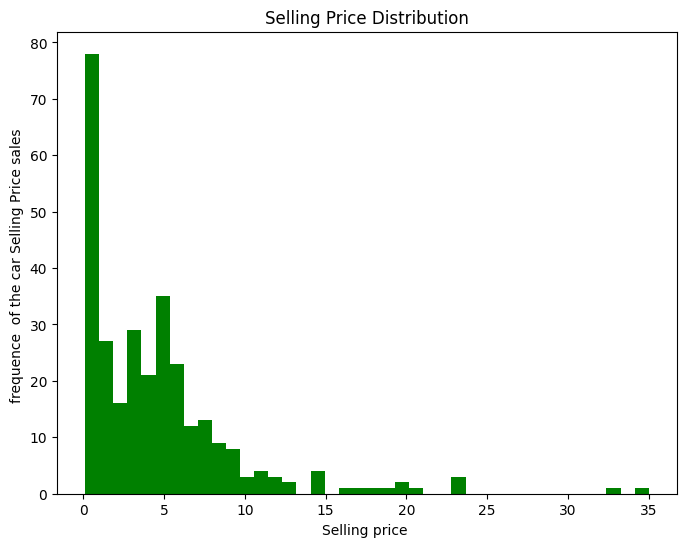

In [11]:
import matplotlib.pylab as plt 

plt.figure(figsize=(8, 6))
plt.hist(data["Selling_Price"],bins=40,color="Green")

plt.title("Selling Price Distribution")
plt.xlabel("Selling price ")
plt.ylabel("frequence  of the car Selling Price sales ")
plt.show()

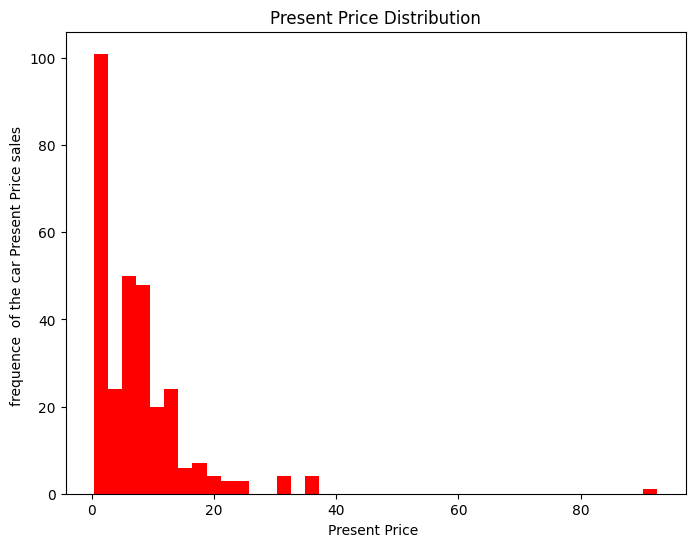

In [12]:
import matplotlib.pylab as plt 

plt.figure(figsize=(8, 6))
plt.hist(data["Present_Price"],bins=40,color="red")

plt.title("Present Price Distribution")
plt.xlabel("Present Price ")
plt.ylabel("frequence  of the car Present Price sales ")
plt.show()

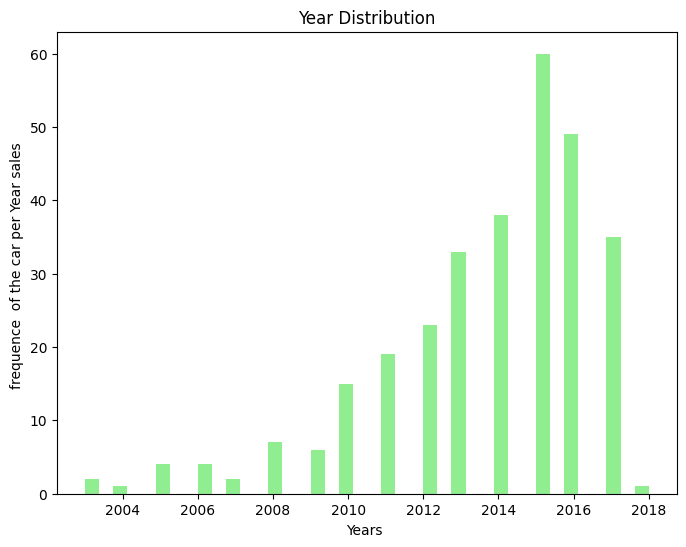

In [13]:
import matplotlib.pylab as plt 

plt.figure(figsize=(8, 6))
plt.hist(data["Year"],bins=40,color="lightGreen")

plt.title("Year Distribution")
plt.xlabel("Years ")
plt.ylabel("frequence  of the car per Year sales ")
plt.show()

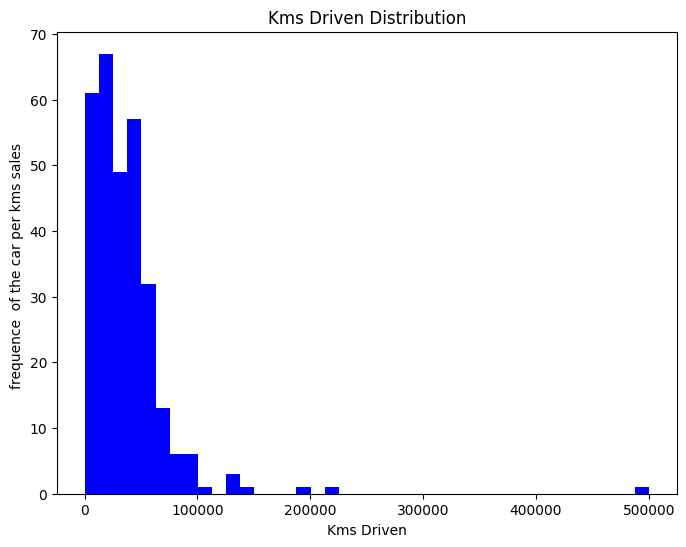

In [14]:
import matplotlib.pylab as plt 


plt.figure(figsize=(8, 6))
plt.hist(data["Kms_Driven"],bins=40,color="Blue")

plt.title("Kms Driven Distribution")
plt.xlabel("Kms Driven")
plt.ylabel("frequence  of the car per kms sales ")
plt.show()

### Categorical Feature Distributions

Count plots summarize the levels of `Fuel_Type`, `Seller_Type`, `Transmission`, and `Owner`. The dataset is dominated by petrol cars, dealer listings, manual transmissions, and vehicles with no previous owner.


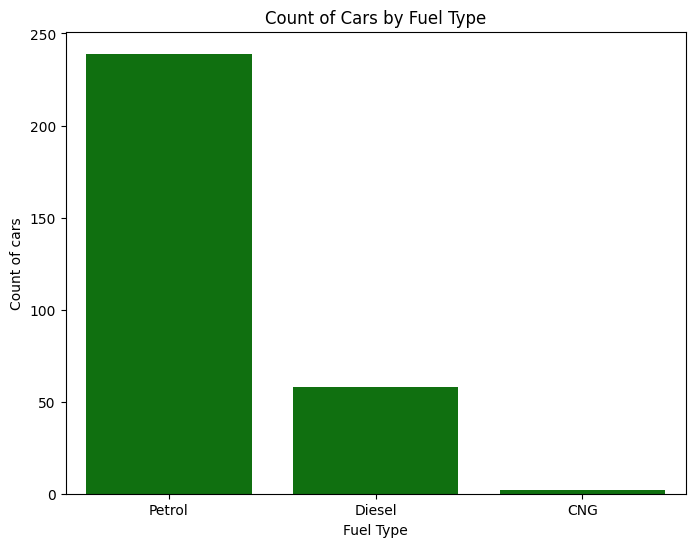

In [15]:
import matplotlib.pylab as plt 
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.countplot(x= data["Fuel_Type"],color="green")

plt.title("Count of Cars by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Count of cars")
plt.show()

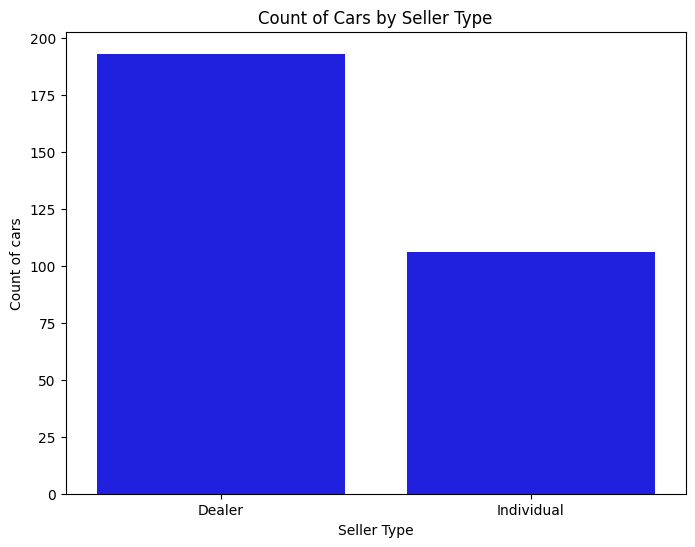

In [16]:
import matplotlib.pylab as plt 
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.countplot(x= data["Seller_Type"],color="Blue")

plt.title("Count of Cars by Seller Type")
plt.xlabel("Seller Type")
plt.ylabel("Count of cars")
plt.show()

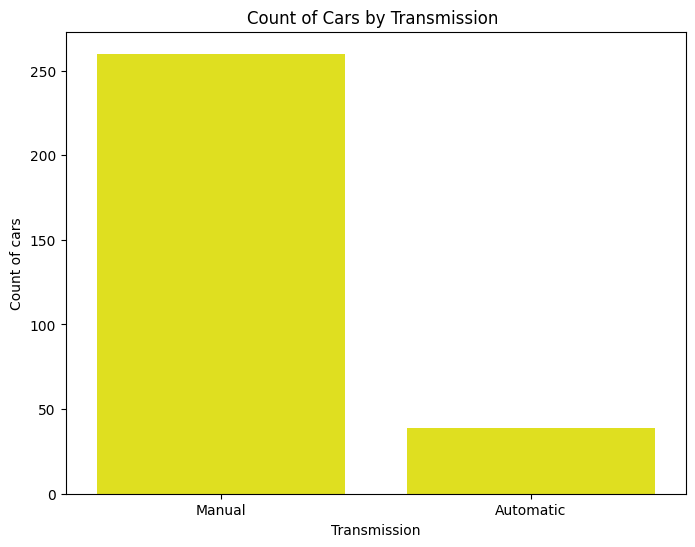

In [17]:
import matplotlib.pylab as plt 
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.countplot(x= data["Transmission"],color="yellow")

plt.title("Count of Cars by Transmission ")
plt.xlabel("Transmission")
plt.ylabel("Count of cars")
plt.show()

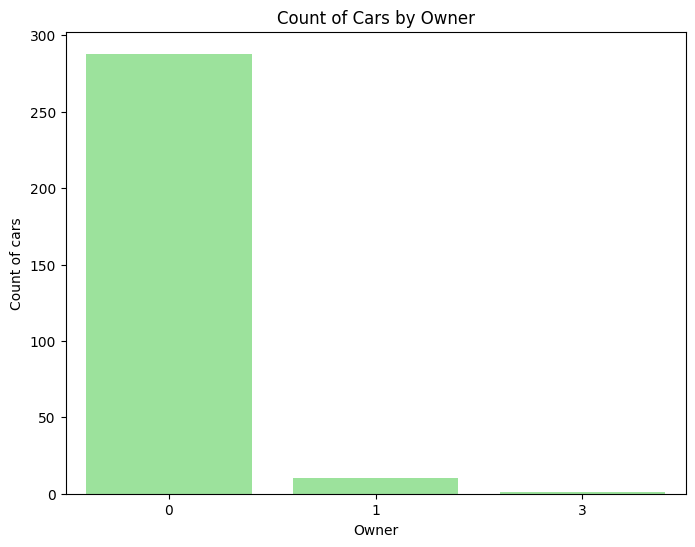

In [18]:
import matplotlib.pylab as plt 
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.countplot(x= data["Owner"],color="lightgreen")

plt.title("Count of Cars by Owner")
plt.xlabel("Owner")
plt.ylabel("Count of cars")
plt.show()

### Bivariate Analysis

Scatter plots compare `Selling_Price` with `Present_Price`, `Year`, and `Kms_Driven`. Boxen plots compare selling-price distributions across fuel type, seller type, transmission, and owner groups. Together, these plots highlight both numerical trends and category-level differences in selling price.


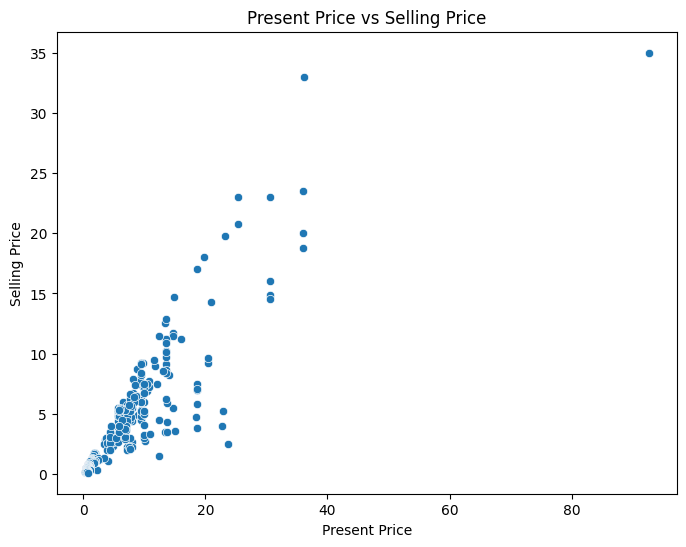

In [19]:
import matplotlib.pylab as plt 
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.scatterplot(x= data["Present_Price"],y= data["Selling_Price"])

plt.title("Present Price vs Selling Price")
plt.xlabel("Present Price")
plt.ylabel("Selling Price")
plt.show()

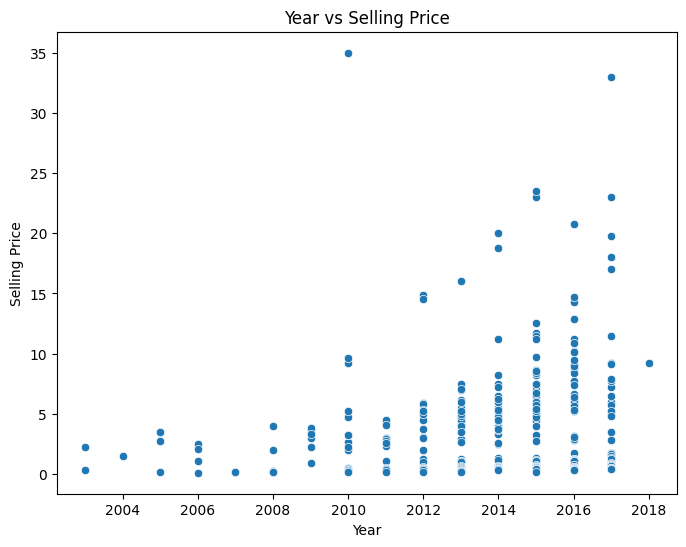

In [20]:
import matplotlib.pylab as plt 
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.scatterplot(x= data["Year"],y= data["Selling_Price"])

plt.title("Year vs Selling Price")
plt.xlabel("Year")
plt.ylabel("Selling Price")
plt.show()

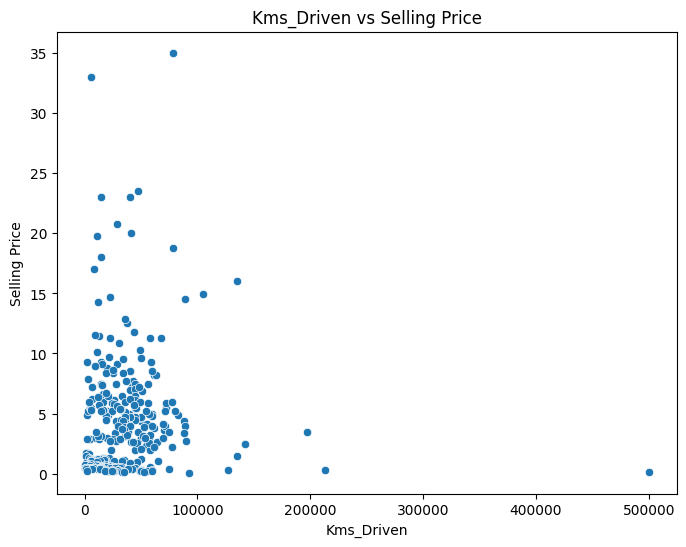

In [21]:
import matplotlib.pylab as plt 
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.scatterplot(x= data["Kms_Driven"],y= data["Selling_Price"])

plt.title("Kms_Driven vs Selling Price")
plt.xlabel("Kms_Driven")
plt.ylabel("Selling Price")
plt.show()

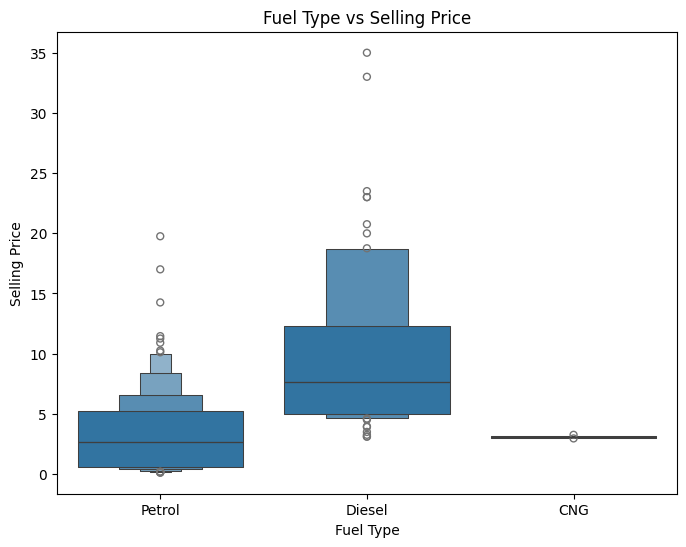

In [22]:
import matplotlib.pylab as plt 
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.boxenplot(x= data["Fuel_Type"],y= data["Selling_Price"])

plt.title("Fuel Type vs Selling Price")
plt.xlabel("Fuel Type")
plt.ylabel("Selling Price")
plt.show()

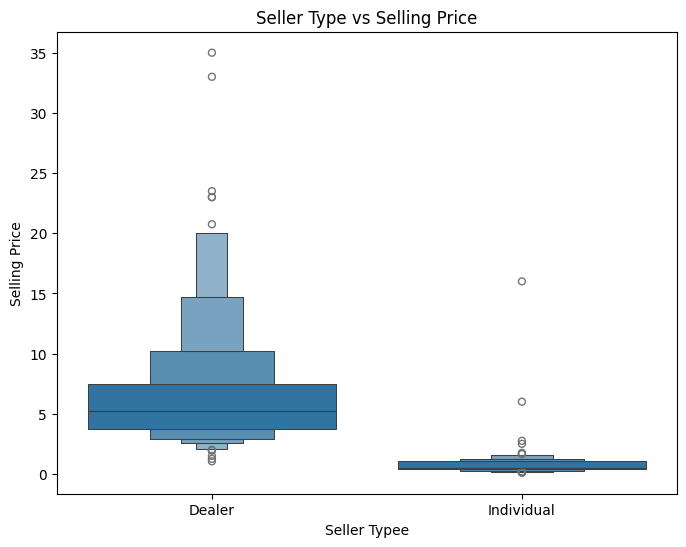

In [23]:
import matplotlib.pylab as plt 
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.boxenplot(x= data["Seller_Type"],y= data["Selling_Price"])

plt.title("Seller Type vs Selling Price")
plt.xlabel("Seller Typee")
plt.ylabel("Selling Price")
plt.show()

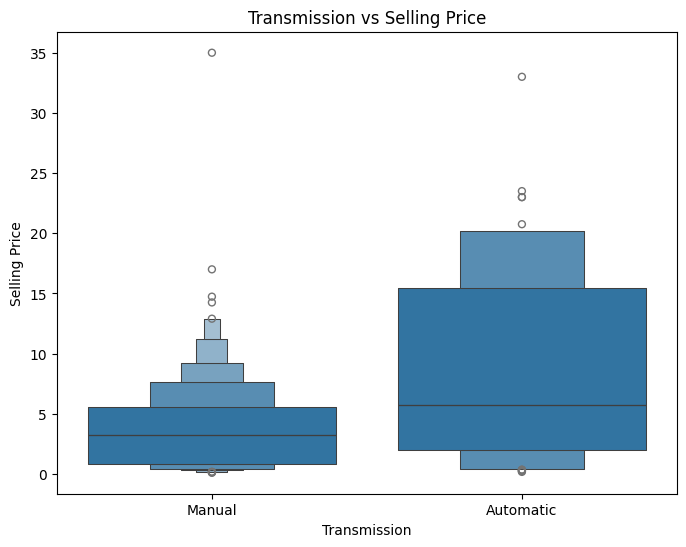

In [24]:
import matplotlib.pylab as plt 
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.boxenplot(x= data["Transmission"],y= data["Selling_Price"])

plt.title("Transmission vs Selling Price")
plt.xlabel("Transmission")
plt.ylabel("Selling Price")
plt.show()

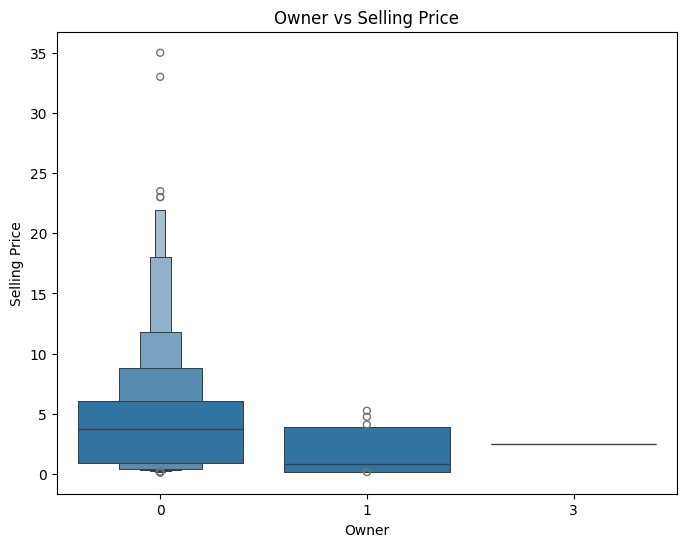

In [25]:
import matplotlib.pylab as plt 
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.boxenplot(x= data["Owner"],y= data["Selling_Price"])

plt.title("Owner vs Selling Price")
plt.xlabel("Owner")
plt.ylabel("Selling Price")
plt.show()

### Correlation Heatmap

The correlation heatmap summarizes linear relationships among the numerical variables. `Present_Price` has the strongest positive association with `Selling_Price`, while `Kms_Driven` shows a negative association. `Year` also trends positively with selling price, whereas `Owner` has only a weak relationship.


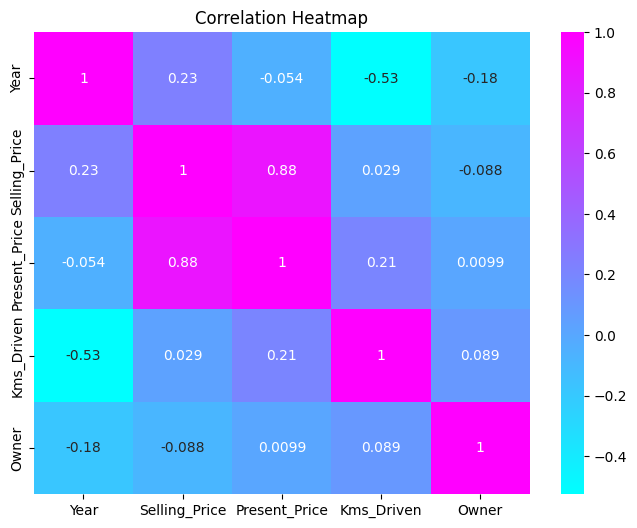

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

numerical_cols = ['Year', 'Selling_Price', 'Present_Price', 'Kms_Driven', 'Owner']

corr_matrix = data[numerical_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='cool')

plt.title("Correlation Heatmap")
plt.show()

### Pair Plot

The pair plot provides a combined view of pairwise relationships and marginal distributions for the selected numerical features. It reinforces the positive relationship between present price and selling price and helps reveal the spread and possible outlying observations.


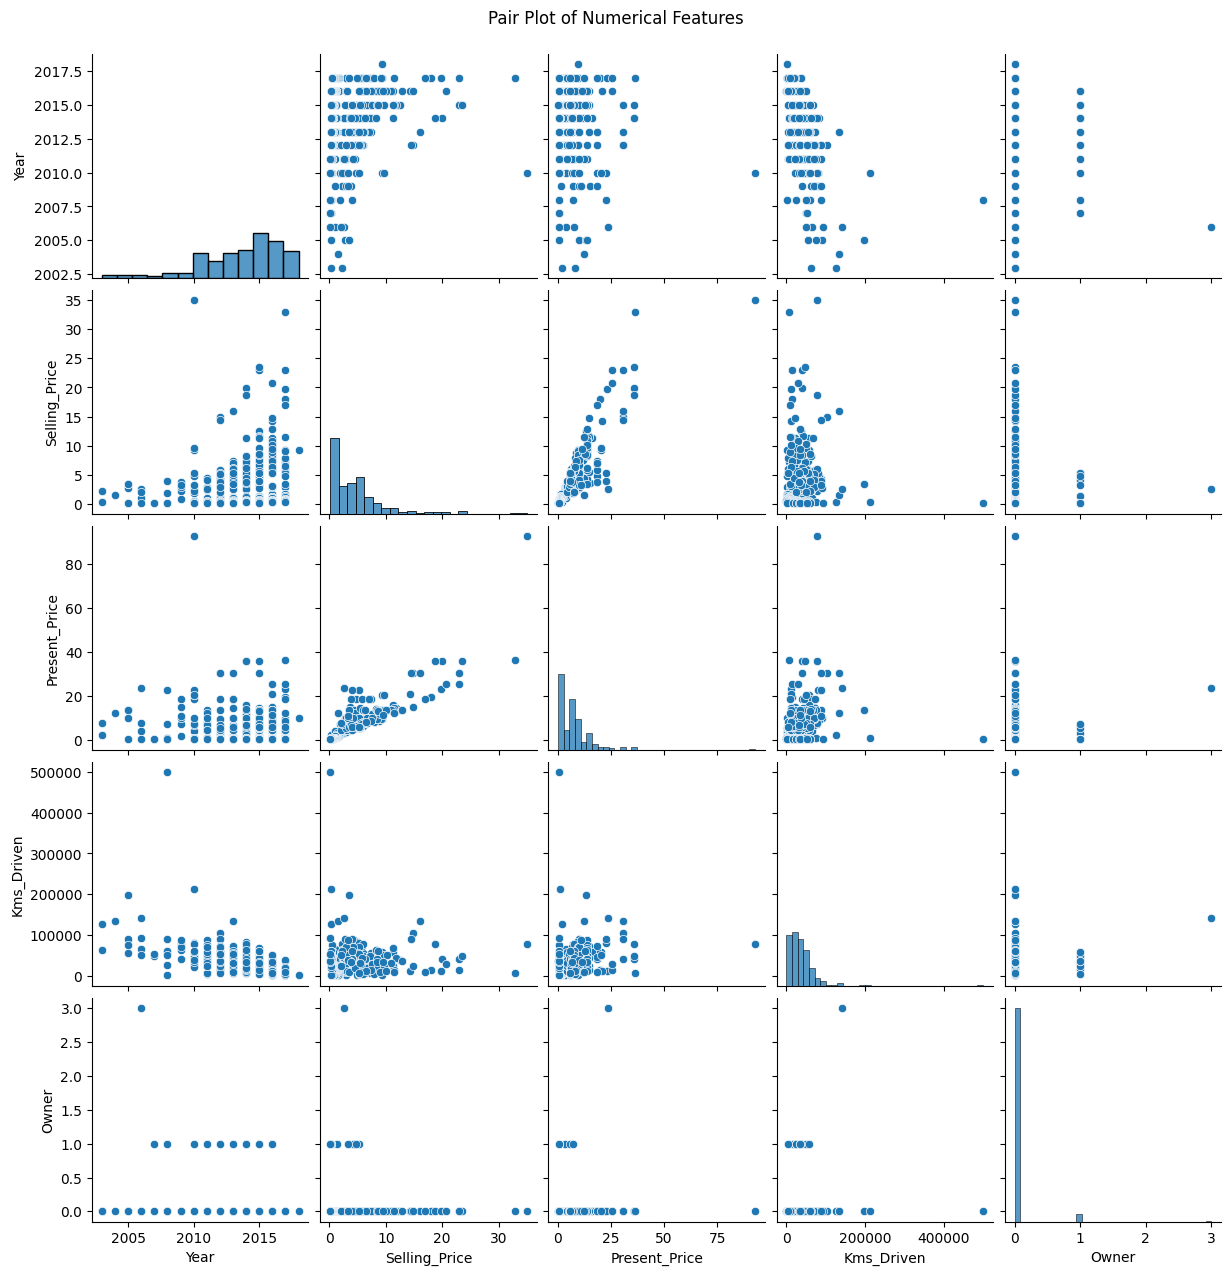

In [27]:
import seaborn as sns
import matplotlib.pyplot as plt

numerical_cols = ['Year', 'Selling_Price', 'Present_Price', 'Kms_Driven', 'Owner']

sns.pairplot(data[numerical_cols])

plt.suptitle("Pair Plot of Numerical Features", y=1.02)
plt.show()

## 7. Key EDA Findings

- The cleaned dataset contains **299 car records and 9 features**.
- There are no missing values; the only data-quality issue identified was two exact duplicate rows.
- `Present_Price` shows the clearest positive relationship with `Selling_Price`.
- Newer vehicles generally have higher selling prices, while higher mileage is generally associated with lower selling prices.
- The categorical variables are imbalanced, with petrol, dealer, and manual-transmission listings appearing most frequently.
- Selling-price distributions vary across fuel type, seller type, transmission, and owner groups, although category sizes should be considered when interpreting these comparisons.
- The numerical plots show skewed ranges and high-value observations, particularly for price and mileage.


## 8. Data Cleaning Decisions

- Loaded the source CSV into a pandas DataFrame without changing the original feature names.
- Verified that all columns contain zero missing values; no rows were imputed or removed for null values.
- Identified and removed two exact duplicate records using `drop_duplicates()`.
- Retained the remaining numerical and categorical features for analysis.
- Preserved the observed distributions and extreme values for EDA rather than applying unrecorded outlier transformations.


In [28]:
data["Car_Age"] = 2018 - data["Year"]
print(data.head())

  Car_Name  Year  Selling_Price  Present_Price  Kms_Driven Fuel_Type  \
0     ritz  2014           3.35           5.59       27000    Petrol   
1      sx4  2013           4.75           9.54       43000    Diesel   
2     ciaz  2017           7.25           9.85        6900    Petrol   
3  wagon r  2011           2.85           4.15        5200    Petrol   
4    swift  2014           4.60           6.87       42450    Diesel   

  Seller_Type Transmission  Owner  Car_Age  
0      Dealer       Manual      0        4  
1      Dealer       Manual      0        5  
2      Dealer       Manual      0        1  
3      Dealer       Manual      0        7  
4      Dealer       Manual      0        4  


In [29]:
print(data["Car_Name"].unique())

<ArrowStringArray>
[                     'ritz',                       'sx4',
                      'ciaz',                   'wagon r',
                     'swift',             'vitara brezza',
                   's cross',                  'alto 800',
                    'ertiga',                     'dzire',
                  'alto k10',                     'ignis',
                       '800',                    'baleno',
                      'omni',                  'fortuner',
                    'innova',             'corolla altis',
               'etios cross',                   'etios g',
                'etios liva',                   'corolla',
                  'etios gd',                     'camry',
              'land cruiser', 'Royal Enfield Thunder 500',
        'UM Renegade Mojave',                 'KTM RC200',
         'Bajaj Dominar 400', 'Royal Enfield Classic 350',
                 'KTM RC390',            'Hyosung GT250R',
 'Royal Enfield Thunder 350',        

In [30]:
car_count = data["Car_Name"].value_counts()
print(car_count.head(10))

Car_Name
city                         26
corolla altis                16
verna                        14
fortuner                     10
brio                         10
ciaz                          9
innova                        9
i20                           9
grand i10                     8
Royal Enfield Classic 350     7
Name: count, dtype: int64


In [31]:
X = data[['Present_Price', 'Kms_Driven', 'Owner', 'Car_Age',
        'Fuel_Type', 'Seller_Type', 'Transmission']]

y = data['Selling_Price']

print("Shape of X:", X.shape)
print("Shape of y:", y.shape)

print("\nInput Features:")
display(X.head())

print("\nTarget Variable:")
display(y.head())

print("\nFeature Columns:")
print(X.columns.tolist())

Shape of X: (299, 7)
Shape of y: (299,)

Input Features:


,Present_Price,Kms_Driven,Owner,Car_Age,Fuel_Type,Seller_Type,Transmission
0,5.59,27000,0,4,Petrol,Dealer,Manual
1,9.54,43000,0,5,Diesel,Dealer,Manual
2,9.85,6900,0,1,Petrol,Dealer,Manual
3,4.15,5200,0,7,Petrol,Dealer,Manual
4,6.87,42450,0,4,Diesel,Dealer,Manual



Target Variable:


0    3.35
1    4.75
2    7.25
3    2.85
4    4.60
Name: Selling_Price, dtype: float64


Feature Columns:
['Present_Price', 'Kms_Driven', 'Owner', 'Car_Age', 'Fuel_Type', 'Seller_Type', 'Transmission']


In [32]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y,test_size=0.20,random_state=42)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (239, 7)
X_test: (60, 7)
y_train: (239,)
y_test: (60,)


In [33]:
print("Training categorical columns:")
display(X_train[['Fuel_Type', 'Seller_Type', 'Transmission']].head())

print("\nTesting categorical columns:")
display(X_test[['Fuel_Type', 'Seller_Type', 'Transmission']].head())

Training categorical columns:


,Fuel_Type,Seller_Type,Transmission
6,Petrol,Dealer,Manual
185,Petrol,Individual,Automatic
187,Petrol,Individual,Manual
148,Petrol,Individual,Manual
31,Petrol,Dealer,Manual



Testing categorical columns:


,Fuel_Type,Seller_Type,Transmission
283,Petrol,Dealer,Manual
267,Diesel,Dealer,Manual
166,Petrol,Individual,Manual
9,Diesel,Dealer,Manual
78,Petrol,Dealer,Automatic


In [34]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

categorical_features = ['Fuel_Type', 'Seller_Type', 'Transmission']

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ],
    remainder='passthrough')

In [35]:
X_train_encoded = preprocessor.fit_transform(X_train)
X_test_encoded = preprocessor.transform(X_test)

print("Encoded training shape:", X_train_encoded.shape)
print("Encoded testing shape:", X_test_encoded.shape)

Encoded training shape: (239, 11)
Encoded testing shape: (60, 11)


## 9. Model Training and Baseline Comparison

Before training, `Car_Age` was engineered as `2018 - Year`. The selected predictors were `Present_Price`, `Kms_Driven`, `Owner`, `Car_Age`, `Fuel_Type`, `Seller_Type`, and `Transmission`. The categorical variables were one-hot encoded, producing 11 model-ready columns, and the data was divided into 239 training records and 60 test records.

Five baseline regression models were trained using the encoded training data and evaluated on the held-out test data:

- Linear Regression
- Decision Tree Regressor
- Random Forest Regressor
- Gradient Boosting Regressor
- Support Vector Regressor (SVR)

The evaluation metrics are:

- **MAE (Mean Absolute Error):** the average absolute difference between actual and predicted prices. Lower values are better.
- **MSE (Mean Squared Error):** the average squared prediction error, which penalizes larger errors more strongly. Lower values are better.
- **RMSE (Root Mean Squared Error):** the square root of MSE, expressed in the same units as the target price. Lower values are better.
- **R? (Coefficient of Determination):** the proportion of target-price variance explained by the model. Higher values are better; a negative value indicates performance below the mean-prediction baseline on the evaluated test set.


In [36]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(random_state=42),
    'Random Forest': RandomForestRegressor(random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42),
    'Support Vector Regressor': SVR()}

results = []

for name, model in models.items():

    model.fit(X_train_encoded, y_train)

    y_pred = model.predict(X_test_encoded)

    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    results.append({
        'Model': name,
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse,
        'R2 Score': r2
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by='R2 Score', ascending=False
).reset_index(drop=True)

display(results_df.round(4))

,Model,MAE,MSE,RMSE,R2 Score
0,Gradient Boosting,1.1349,6.3667,2.5232,0.7530
1,Linear Regression,1.4729,6.3708,2.5240,0.7528
2,Decision Tree,1.3273,8.4855,2.9130,0.6708
3,Random Forest,1.5270,13.7505,3.7082,0.4665
4,Support Vector Regressor,3.1295,28.3205,5.3217,-0.0988


## 10. Hyperparameter Tuning

`RandomizedSearchCV` was used to sample 50 hyperparameter combinations for each ensemble model. Each candidate was evaluated with **five-fold cross-validation** on the training data using negative RMSE as the scoring objective. In five-fold cross-validation, the training data is divided into five parts and each part is used once as the validation fold while the other four parts are used for fitting.

The tuning covered:

- **Random Forest:** number of estimators, maximum depth, minimum samples for splitting and leaves, and the number of features considered at each split.
- **Gradient Boosting:** number of estimators, learning rate, maximum depth, minimum samples for splitting and leaves, and subsampling rate.

The tuned models were then evaluated on the same held-out test set. In these observed results, tuning did not improve test-set performance over the baseline versions. This can occur because cross-validation optimizes average training-fold validation performance, while the single test split may have different characteristics; the small dataset also makes results sensitive to the particular split.


In [37]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV
from sklearn.pipeline import Pipeline

rf_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(random_state=42))
])

In [38]:
param_dist = {
    'model__n_estimators': [100, 200, 300, 400, 500],
    'model__max_depth': [None, 5, 10, 15, 20, 30],
    'model__min_samples_split': [2, 5, 10, 15],
    'model__min_samples_leaf': [1, 2, 4, 6],
    'model__max_features': ['sqrt', 'log2', 1.0]}

random_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_dist,
    n_iter=50,
    cv=5,
    scoring='neg_root_mean_squared_error',
    random_state=42,
    n_jobs=-1,
    verbose=1)

random_search.fit(X_train, y_train)

Fitting 5 folds for each of 50 candidates, totalling 250 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'model__max_depth': [None, 5, ...], 'model__max_features': ['sqrt', 'log2', ...], 'model__min_samples_leaf': [1, 2, ...], 'model__min_samples_split': [2, 5, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",50
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a be

In [39]:
print("Best Hyperparameters:")
print(random_search.best_params_)

print("\nBest Cross-Validation RMSE:")
print(-random_search.best_score_)

Best Hyperparameters:
{'model__n_estimators': 100, 'model__min_samples_split': 2, 'model__min_samples_leaf': 2, 'model__max_features': 1.0, 'model__max_depth': 20}

Best Cross-Validation RMSE:
1.543609496027405


In [40]:
best_rf_model = random_search.best_estimator_

y_pred_rf = best_rf_model.predict(X_test)

mae_rf = mean_absolute_error(y_test, y_pred_rf)
mse_rf = mean_squared_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mse_rf)
r2_rf = r2_score(y_test, y_pred_rf)

print("Tuned Random Forest Results")
print("MAE:", mae_rf)
print("MSE:", mse_rf)
print("RMSE:", rmse_rf)
print("R2 Score:", r2_rf)

Tuned Random Forest Results
MAE: 1.385108412397788
MSE: 10.665876683914712
RMSE: 3.2658653805560807
R2 Score: 0.5861650499672338


In [41]:
from sklearn.ensemble import GradientBoostingRegressor
gb_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', GradientBoostingRegressor(random_state=42))])

gb_param_dist = {
    'model__n_estimators': [50, 100, 150, 200, 300],
    'model__learning_rate': [0.01, 0.03, 0.05, 0.1, 0.2],
    'model__max_depth': [2, 3, 4, 5],
    'model__min_samples_split': [2, 5, 10],
    'model__min_samples_leaf': [1, 2, 4],
    'model__subsample': [0.7, 0.8, 0.9, 1.0]}

gb_random_search = RandomizedSearchCV(
    estimator=gb_pipeline,
    param_distributions=gb_param_dist,
    n_iter=50,
    cv=5,
    scoring='neg_root_mean_squared_error',
    random_state=42,
    n_jobs=-1,
    verbose=1)

gb_random_search.fit(X_train, y_train)

Fitting 5 folds for each of 50 candidates, totalling 250 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'model__learning_rate': [0.01, 0.03, ...], 'model__max_depth': [2, 3, ...], 'model__min_samples_leaf': [1, 2, ...], 'model__min_samples_split': [2, 5, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",50
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best est

In [42]:
print("Best Gradient Boosting Hyperparameters:")
print(gb_random_search.best_params_)

print("\nBest Cross-Validation RMSE:")
print(-gb_random_search.best_score_)

Best Gradient Boosting Hyperparameters:
{'model__subsample': 0.8, 'model__n_estimators': 300, 'model__min_samples_split': 5, 'model__min_samples_leaf': 4, 'model__max_depth': 4, 'model__learning_rate': 0.1}

Best Cross-Validation RMSE:
1.381736789861521


In [43]:
best_gb_model = gb_random_search.best_estimator_

y_pred_gb = best_gb_model.predict(X_test)

mae_gb = mean_absolute_error(y_test, y_pred_gb)
mse_gb = mean_squared_error(y_test, y_pred_gb)
rmse_gb = np.sqrt(mse_gb)
r2_gb = r2_score(y_test, y_pred_gb)

print("Tuned Gradient Boosting Results")
print("MAE:", mae_gb)
print("MSE:", mse_gb)
print("RMSE:", rmse_gb)
print("R2 Score:", r2_gb)

Tuned Gradient Boosting Results
MAE: 1.3015601075426824
MSE: 9.434320752906224
RMSE: 3.0715339413567
R2 Score: 0.6339492970830924


## 11. Feature Importance Analysis

Feature importance was examined using the baseline Gradient Boosting model. `Present_Price` was the most influential feature by a wide margin, followed by `Car_Age`. This is consistent with the EDA: a car's current market price provides a strong signal of its selling price, while vehicle age captures depreciation over time. The remaining numerical and one-hot encoded categorical features contributed much smaller importance values in this fitted model.


,Feature,Importance
7,remainder__Present_Price,0.898545
10,remainder__Car_Age,0.074910
8,remainder__Kms_Driven,0.009688
5,cat__Transmission_Automatic,0.005286
1,cat__Fuel_Type_Diesel,0.004270
6,cat__Transmission_Manual,0.003892
2,cat__Fuel_Type_Petrol,0.003307
3,cat__Seller_Type_Dealer,0.000071
4,cat__Seller_Type_Individual,0.000025
0,cat__Fuel_Type_CNG,0.000004


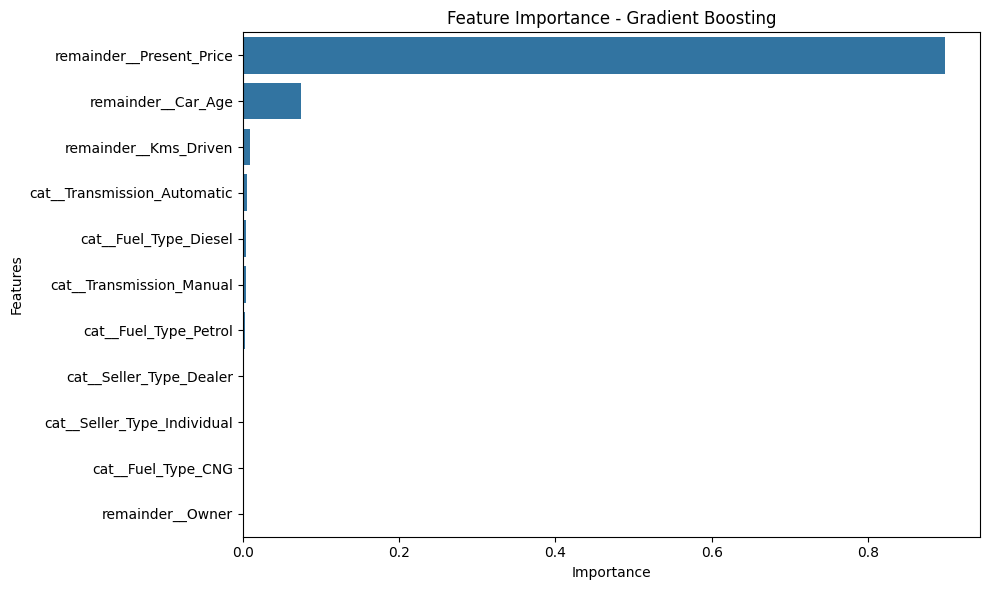

In [44]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

gb_model = GradientBoostingRegressor(random_state=42)
gb_model.fit(X_train_encoded, y_train)

feature_importance = pd.DataFrame({
    'Feature': preprocessor.get_feature_names_out(),
    'Importance': gb_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance', ascending=False
)

display(feature_importance)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=feature_importance,
    x='Importance',
    y='Feature'
)
plt.title('Feature Importance - Gradient Boosting')
plt.xlabel('Importance')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

## 12. Final Model Comparison

The final comparison table brings together the test-set results for all seven evaluated models: the five baseline models plus the tuned Random Forest and tuned Gradient Boosting models. The table is sorted by R? score in descending order and reports MAE, MSE, RMSE, and R? for a consistent comparison of accuracy and explained variance.


In [45]:
final_results = pd.DataFrame([
    {
        'Model': 'Linear Regression',
        'MAE': 1.4729, 'MSE': 6.3708,
        'RMSE': 2.5240, 'R2 Score': 0.7528
    },
    {
        'Model': 'Decision Tree',
        'MAE': 1.3273, 'MSE': 8.4855,
        'RMSE': 2.9130, 'R2 Score': 0.6708
    },
    {
        'Model': 'Random Forest (Baseline)',
        'MAE': 1.5270, 'MSE': 13.7505,
        'RMSE': 3.7082, 'R2 Score': 0.4665
    },
    {
        'Model': 'Gradient Boosting (Baseline)',
        'MAE': 1.1349, 'MSE': 6.3667,
        'RMSE': 2.5232, 'R2 Score': 0.7530
    },
    {
        'Model': 'SVR (Baseline)',
        'MAE': 3.1295, 'MSE': 28.3205,
        'RMSE': 5.3217, 'R2 Score': -0.0988
    },
    {
        'Model': 'Random Forest (Tuned)',
        'MAE': 1.3851, 'MSE': 10.6659,
        'RMSE': 3.2659, 'R2 Score': 0.5862
    },
    {
        'Model': 'Gradient Boosting (Tuned)',
        'MAE': 1.3016, 'MSE': 9.4343,
        'RMSE': 3.0715, 'R2 Score': 0.6339
    }
])

final_results = final_results.sort_values(
    by='R2 Score', ascending=False
).reset_index(drop=True)

display(final_results.round(4))

,Model,MAE,MSE,RMSE,R2 Score
0,Gradient Boosting (Baseline),1.1349,6.3667,2.5232,0.7530
1,Linear Regression,1.4729,6.3708,2.5240,0.7528
2,Decision Tree,1.3273,8.4855,2.9130,0.6708
3,Gradient Boosting (Tuned),1.3016,9.4343,3.0715,0.6339
4,Random Forest (Tuned),1.3851,10.6659,3.2659,0.5862
5,Random Forest (Baseline),1.5270,13.7505,3.7082,0.4665
6,SVR (Baseline),3.1295,28.3205,5.3217,-0.0988


## 13. Final Model Selection

The **baseline Gradient Boosting** model was selected as the best-performing model based on the observed test results. It achieved an **R? score of 0.7530** and an **RMSE of 2.5232**, with the lowest MAE among the compared models. It was selected because it explained the largest proportion of variation in selling price while producing the lowest overall prediction error in the reported comparison.


In [46]:
import joblib

final_model_artifact = {
    'preprocessor': preprocessor,
    'model': gb_model
}

joblib.dump(
    final_model_artifact,
    'best_car_price_model.pkl'
)

print("Final model saved successfully!")

Final model saved successfully!


## 14. Conclusion

This project analyzed used-car selling prices using a cleaned dataset of 299 records. The work included loading and inspecting the data, confirming data types and missing values, removing two exact duplicates, and exploring numerical and categorical variables through distributions, bivariate plots, a correlation heatmap, and a pair plot. The analysis identified `Present_Price` as the strongest observed pricing-related variable and showed meaningful relationships with vehicle age and mileage.

For modeling, `Car_Age` was engineered from `Year`, categorical features were one-hot encoded, and the data was split into training and test sets. Five baseline regression models were trained and evaluated with MAE, MSE, RMSE, and R?. Randomized hyperparameter searches with five-fold cross-validation were then performed for Random Forest and Gradient Boosting. The final comparison showed that baseline Gradient Boosting performed best on the observed test split, with an R? of 0.7530 and RMSE of 2.5232. Feature importance analysis further showed that `Present_Price` and `Car_Age` dominated the fitted Gradient Boosting model's predictions.


## 15. Limitations

- The dataset is relatively small, with 299 records after duplicate removal, so model results may vary across different train-test splits.
- SVR was included in the baseline comparison without feature scaling, which may have limited its performance because its input features are measured on different scales.
- Baseline model selection involved examining the test-set results. Therefore, the reported test performance should be interpreted as exploratory rather than as an entirely unbiased final estimate.
